## **Mount Google Drive and create project folders**

In [1]:
from google.colab import drive
import os
import time


def mount_drive(retries=3):
    """
    Mount Google Drive with automatic retry handling.
    Args:
        retries (int): Number of mount attempts.
    Returns:
        bool: True if Drive is mounted successfully, otherwise False.
    """
    for attempt in range(retries):
        try:
            # Unmount any existing Drive connection
            try:
                drive.flush_and_unmount()
            except:
                pass

            drive.mount('/content/drive', force_remount=True)
            time.sleep(5)

            # Verify Drive access
            os.listdir('/content/drive/MyDrive')

            print(f"Drive mounted successfully (attempt {attempt + 1})")
            return True

        except Exception as e:
            print(f"Mount attempt {attempt + 1} failed: {e}")
            time.sleep(10)

    print("Drive could not be mounted")
    return False


# Mount Google Drive
mount_drive()

# Project root directory
PROJECT = '/content/drive/MyDrive/fake_image_detection'

# Project directories stored in Google Drive
DIRS = [
    f'{PROJECT}/data/celeb_df',
    f'{PROJECT}/data/casia',
    f'{PROJECT}/data/frames/real',
    f'{PROJECT}/data/frames/fake',
    f'{PROJECT}/data/ela/real',
    f'{PROJECT}/data/ela/fake',
    f'{PROJECT}/data/dft/real',
    f'{PROJECT}/data/dft/fake',
    f'{PROJECT}/models',
    f'{PROJECT}/logs',
    f'{PROJECT}/outputs',
    f'{PROJECT}/predictions'
]

for directory in DIRS:
    os.makedirs(directory, exist_ok=True)

# Local runtime directories used during processing
LOCAL_DIRS = [
    '/content/frames/real',
    '/content/frames/fake',
    '/content/ela/real',
    '/content/ela/fake',
    '/content/dft/real',
    '/content/dft/fake'
]

for directory in LOCAL_DIRS:
    os.makedirs(directory, exist_ok=True)

print("All folders are ready")

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive
Drive mounted successfully (attempt 1)
All folders are ready


## **Install Libraries**

In [2]:
# Install OpenCV for image and video processing
!pip install -q opencv-python-headless

# Standard libraries
import io
import os
import time
import random
import shutil
from collections import Counter

# Numerical computing
import numpy as np

# Computer vision
import cv2

# Image processing
from PIL import Image, ImageChops, ImageEnhance

# Visualisation
import matplotlib.pyplot as plt

# Progress tracking
from tqdm import tqdm

# Google Drive access
from google.colab import drive

print("Libraries imported successfully")

Libraries imported successfully


## **Define project paths**

In [3]:
# Source dataset directories
CELEB_REAL = f'{PROJECT}/data/celeb_df/Celeb-real'
CELEB_FAKE = f'{PROJECT}/data/celeb_df/Celeb-synthesis'
CELEB_YT = f'{PROJECT}/data/celeb_df/YouTube-real'

CASIA_REAL = f'{PROJECT}/data/casia/Au'
CASIA_FAKE = f'{PROJECT}/data/casia/Tp'

# Processed data directories
FRAMES_REAL = f'{PROJECT}/data/frames/real'
FRAMES_FAKE = f'{PROJECT}/data/frames/fake'

ELA_REAL = f'{PROJECT}/data/ela/real'
ELA_FAKE = f'{PROJECT}/data/ela/fake'

DFT_REAL = f'{PROJECT}/data/dft/real'
DFT_FAKE = f'{PROJECT}/data/dft/fake'

# Log file paths
LOG_CELEB_REAL = f'{PROJECT}/logs/Celeb-real_done.txt'
LOG_CELEB_YT = f'{PROJECT}/logs/YouTube-real_done.txt'
LOG_CELEB_FAKE = f'{PROJECT}/logs/Celeb-fake_done.txt'

# Local runtime directories used during processing
LOCAL_FRAMES_REAL = '/content/frames/real'
LOCAL_FRAMES_FAKE = '/content/frames/fake'

LOCAL_ELA_REAL = '/content/ela/real'
LOCAL_ELA_FAKE = '/content/ela/fake'

LOCAL_DFT_REAL = '/content/dft/real'
LOCAL_DFT_FAKE = '/content/dft/fake'

print("All paths defined")

All paths defined


## **Copy frames to local disk**

In [4]:
def copy_in_batches(src, dst, label, batch_size=500):
    """
    Copy files from Google Drive to local storage in batches.

    Existing files are skipped, allowing the process to be
    safely resumed after interruptions.

    Args:
        src (str): Source directory.
        dst (str): Destination directory.
        label (str): Dataset label for progress messages.
        batch_size (int): Number of files copied per batch.
    """
    if not os.path.exists(src):
        print(f"{label}: Source directory not found")
        return

    try:
        all_files = os.listdir(src)
    except OSError:
        print(f"{label}: Unable to access source directory")
        return

    local_files = set(os.listdir(dst))
    files_to_copy = [file for file in all_files if file not in local_files]

    print(
        f"\n{label}: {len(all_files)} on Drive | "
        f"{len(local_files)} local | {len(files_to_copy)} remaining"
    )

    if not files_to_copy:
        print("All files already copied")
        return

    copied = 0
    batches = [
        files_to_copy[i:i + batch_size]
        for i in range(0, len(files_to_copy), batch_size)
    ]

    for batch_index, batch in enumerate(batches, start=1):
        print(
            f"Batch {batch_index}/{len(batches)}...",
            end=' ',
            flush=True
        )

        for file in batch:
            try:
                shutil.copy(
                    os.path.join(src, file),
                    os.path.join(dst, file)
                )
                copied += 1
            except Exception:
                pass

        print("Complete")
        time.sleep(1)

    print(
        f"Copied {copied} files | "
        f"{len(os.listdir(dst))} total files available locally"
    )

# Copy frame datasets to local storage
print("Copying frames to local storage")

copy_in_batches(
    FRAMES_REAL,
    LOCAL_FRAMES_REAL,
    'Real frames'
)

copy_in_batches(
    FRAMES_FAKE,
    LOCAL_FRAMES_FAKE,
    'Fake frames'
)

# Display local file counts
print("\nLocal storage status")
print(f"Real frames: {len(os.listdir(LOCAL_FRAMES_REAL))}")
print(f"Fake frames: {len(os.listdir(LOCAL_FRAMES_FAKE))}")

Copying frames to local storage

Real frames: 33882 on Drive | 0 local | 33882 remaining
Batch 1/68... Complete
Batch 2/68... Complete
Batch 3/68... Complete
Batch 4/68... Complete
Batch 5/68... Complete
Batch 6/68... Complete
Batch 7/68... Complete
Batch 8/68... Complete
Batch 9/68... Complete
Batch 10/68... Complete
Batch 11/68... Complete
Batch 12/68... Complete
Batch 13/68... Complete
Batch 14/68... Complete
Batch 15/68... Complete
Batch 16/68... Complete
Batch 17/68... Complete
Batch 18/68... Complete
Batch 19/68... Complete
Batch 20/68... Complete
Batch 21/68... Complete
Batch 22/68... Complete
Batch 23/68... Complete
Batch 24/68... Complete
Batch 25/68... Complete
Batch 26/68... Complete
Batch 27/68... Complete
Batch 28/68... Complete
Batch 29/68... Complete
Batch 30/68... Complete
Batch 31/68... Complete
Batch 32/68... Complete
Batch 33/68... Complete
Batch 34/68... Complete
Batch 35/68... Complete
Batch 36/68... Complete
Batch 37/68... Complete
Batch 38/68... Complete
Batch 39

## **Copy CASIA v2 images to local frames folders**

In [5]:
def copy_casia(src_dir, dst_dir, label):
    """
    Copy CASIA v2 images from the source directory to local storage.

    Existing files are skipped to allow safe re-execution.

    Args:
        src_dir (str): Source directory containing CASIA images.
        dst_dir (str): Destination directory.
        label (str): Dataset label used in progress messages.
    """
    os.makedirs(dst_dir, exist_ok=True)

    image_files = [
        file for file in os.listdir(src_dir)
        if file.lower().endswith(('.jpg', '.png', '.tif', '.bmp'))
    ]

    copied = 0
    skipped = 0

    for file in tqdm(image_files, desc=f"CASIA {label}"):
        destination = os.path.join(dst_dir, file)

        if os.path.exists(destination):
            skipped += 1
            continue

        try:
            shutil.copy(
                os.path.join(src_dir, file),
                destination
            )
            copied += 1

        except Exception:
            pass

    print(f"CASIA {label}: {copied} copied | {skipped} skipped")

# Copy authentic and tampered CASIA images
copy_casia(
    CASIA_REAL,
    LOCAL_FRAMES_REAL,
    'authentic'
)

copy_casia(
    CASIA_FAKE,
    LOCAL_FRAMES_FAKE,
    'tampered'
)

# Display final image counts
print(f"\nTotal real images: {len(os.listdir(LOCAL_FRAMES_REAL))}")
print(f"Total fake images: {len(os.listdir(LOCAL_FRAMES_FAKE))}")

CASIA authentic: 100%|██████████| 7491/7491 [00:00<00:00, 222971.13it/s]


CASIA authentic: 0 copied | 7491 skipped


CASIA tampered: 100%|██████████| 5123/5123 [06:21<00:00, 13.42it/s] 

CASIA tampered: 5123 copied | 0 skipped

Total real images: 33882
Total fake images: 5123


## **Check and balance the dataset classes**

Class distribution before balancing
Real images: 33828
Fake images: 2064
Ratio: 16.39

Class distribution after balancing
Real images: 2064
Fake images: 2064
Total images: 4128
Ratio: 1.00

Balanced file lists saved
These lists will be used by all project notebooks


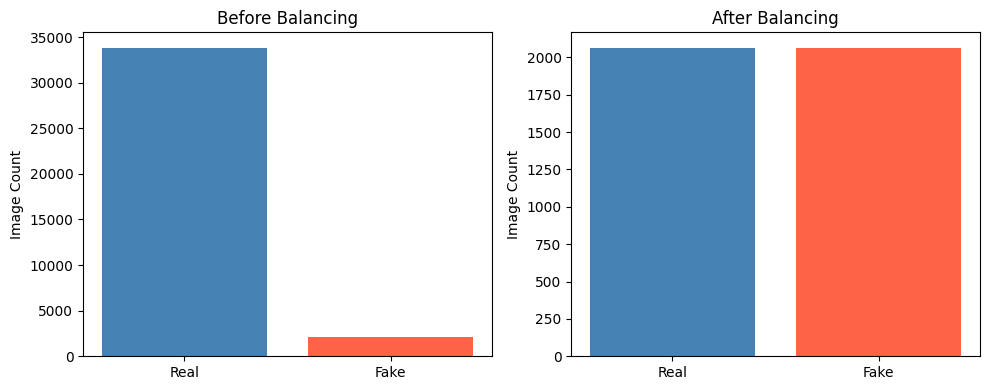

Class balance chart saved


In [6]:
# Load image filenames from both classes
real_files = [
    file for file in os.listdir(LOCAL_FRAMES_REAL)
    if file.lower().endswith(('.jpg', '.png'))
]

fake_files = [
    file for file in os.listdir(LOCAL_FRAMES_FAKE)
    if file.lower().endswith(('.jpg', '.png'))
]

# Display class distribution before balancing
print("Class distribution before balancing")
print(f"Real images: {len(real_files)}")
print(f"Fake images: {len(fake_files)}")
print(f"Ratio: {len(real_files) / len(fake_files):.2f}")

# Balance the dataset by undersampling the majority class
min_count = min(len(real_files), len(fake_files))

random.seed(42)

real_balanced = set(
    random.sample(real_files, min_count)
)

fake_balanced = set(
    random.sample(fake_files, min_count)
)

# Save balanced file lists for reuse across notebooks
balanced_dir = f'{PROJECT}/data/balanced'
os.makedirs(balanced_dir, exist_ok=True)

with open(f'{balanced_dir}/real_files.txt', 'w') as file:
    file.write('\n'.join(sorted(real_balanced)))

with open(f'{balanced_dir}/fake_files.txt', 'w') as file:
    file.write('\n'.join(sorted(fake_balanced)))

# Display class distribution after balancing
print("\nClass distribution after balancing")
print(f"Real images: {min_count}")
print(f"Fake images: {min_count}")
print(f"Total images: {min_count * 2}")
print("Ratio: 1.00")

print("\nBalanced file lists saved")
print("These lists will be used by all project notebooks")

# Visualise class balance before and after balancing
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(
    ['Real', 'Fake'],
    [len(real_files), len(fake_files)],
    color=['steelblue', 'tomato']
)
axes[0].set_title('Before Balancing')
axes[0].set_ylabel('Image Count')

axes[1].bar(
    ['Real', 'Fake'],
    [min_count, min_count],
    color=['steelblue', 'tomato']
)
axes[1].set_title('After Balancing')
axes[1].set_ylabel('Image Count')

plt.tight_layout()

# Save the balance visualisation
plt.savefig(
    f'{PROJECT}/outputs/class_balance.png',
    dpi=150
)

plt.show()

print("Class balance chart saved")

## **Compute ELA maps**

In [7]:
def compute_ela(image_path, quality=90, scale=15):
    """
    Generate an Error Level Analysis (ELA) image.

    Args:
        image_path (str): Path to the source image.
        quality (int): JPEG recompression quality.
        scale (int): Brightness scaling factor.

    Returns:
        PIL.Image or None: ELA image if successful, otherwise None.
    """
    try:
        original = Image.open(image_path).convert('RGB')

        buffer = io.BytesIO()
        original.save(buffer, 'JPEG', quality=quality)
        buffer.seek(0)

        recompressed = Image.open(buffer).convert('RGB')

        ela_image = ImageChops.difference(
            original,
            recompressed
        )

        extrema = ela_image.getextrema()
        max_diff = max(value[1] for value in extrema) or 1

        ela_image = ImageEnhance.Brightness(
            ela_image
        ).enhance(255.0 / max_diff * scale)

        return ela_image

    except Exception:
        return None


def process_ela(file_list, source_dir, ela_dir, label):
    """
    Generate ELA images for a balanced dataset.

    Both the original image and its ELA representation are
    stored in the destination directory. Previously processed
    files are skipped.

    Args:
        file_list (list): Images to process.
        source_dir (str): Source image directory.
        ela_dir (str): Destination directory.
        label (str): Dataset label.
    """
    os.makedirs(ela_dir, exist_ok=True)

    processed = 0
    skipped = 0
    failed = 0

    for image_name in tqdm(file_list, desc=f"ELA {label}"):

        source_path = os.path.join(source_dir, image_name)
        destination_path = os.path.join(ela_dir, image_name)

        ela_name = (
            image_name.replace('.jpg', '_ela.jpg')
            .replace('.png', '_ela.png')
        )

        ela_path = os.path.join(ela_dir, ela_name)

        if os.path.exists(ela_path) and os.path.exists(destination_path):
            skipped += 1
            continue

        ela_image = compute_ela(source_path)

        if ela_image is not None:
            ela_image.save(ela_path)
            shutil.copy(source_path, destination_path)
            processed += 1
        else:
            failed += 1

    print(
        f"\n{label} ELA: {processed} processed | "
        f"{skipped} skipped | {failed} failed"
    )
    print(f"Total files: {len(os.listdir(ela_dir))}")


# Load balanced image lists
with open(f'{PROJECT}/data/balanced/real_files.txt') as file:
    real_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

with open(f'{PROJECT}/data/balanced/fake_files.txt') as file:
    fake_balanced = [
        line.strip()
        for line in file
        if line.strip()
    ]

print(
    f"Computing ELA for {len(real_balanced)} real images "
    f"and {len(fake_balanced)} fake images\n"
)

# Generate ELA images
process_ela(
    real_balanced,
    LOCAL_FRAMES_REAL,
    LOCAL_ELA_REAL,
    'real'
)

process_ela(
    fake_balanced,
    LOCAL_FRAMES_FAKE,
    LOCAL_ELA_FAKE,
    'fake'
)

print("\nSaving ELA images to Drive")


def save_to_drive(local_dir, drive_dir, label):
    """
    Copy locally generated ELA files to Google Drive.

    Args:
        local_dir (str): Local source directory.
        drive_dir (str): Drive destination directory.
        label (str): Dataset label.
    """
    os.makedirs(drive_dir, exist_ok=True)

    files = os.listdir(local_dir)
    copied = 0

    for file_name in tqdm(files, desc=f"Saving {label}"):

        destination = os.path.join(drive_dir, file_name)

        if not os.path.exists(destination):
            try:
                shutil.copy(
                    os.path.join(local_dir, file_name),
                    destination
                )
                copied += 1

            except Exception:
                pass

    print(f"{label}: {copied} files saved")

# Save generated ELA files to Drive
save_to_drive(
    LOCAL_ELA_REAL,
    ELA_REAL,
    'ELA real'
)

save_to_drive(
    LOCAL_ELA_FAKE,
    ELA_FAKE,
    'ELA fake'
)

print("ELA generation complete")

Computing ELA for 2064 real images and 2064 fake images



ELA real: 100%|██████████| 2064/2064 [00:37<00:00, 54.49it/s]



real ELA: 2064 processed | 0 skipped | 0 failed
Total files: 4128


ELA fake: 100%|██████████| 2064/2064 [00:24<00:00, 84.98it/s]



fake ELA: 2064 processed | 0 skipped | 0 failed
Total files: 4128

Saving ELA images to Drive


Saving ELA real: 100%|██████████| 4128/4128 [00:00<00:00, 7004.21it/s]


ELA real: 0 files saved


Saving ELA fake: 100%|██████████| 4128/4128 [00:00<00:00, 5764.18it/s]

ELA fake: 0 files saved
ELA generation complete


## **Compute DFT spectrograms**

In [8]:
def compute_dft(image_path):
    """
    Compute a 2D Discrete Fourier Transform (DFT) magnitude spectrum.

    The image is converted to grayscale, transformed into the frequency domain,
    and shifted so that the low-frequency components are centered. The result
    is log-scaled and converted into a 3-channel RGB image.

    Args:
        image_path (str): Path to input image.

    Returns:
        PIL.Image or None: DFT magnitude spectrogram as an RGB image.
    """
    try:
        image = Image.open(image_path).convert('L')
        image_np = np.array(image, dtype=np.float32)

        # Compute 2D FFT and shift zero-frequency component to centre
        dft = np.fft.fft2(image_np)
        dft_shifted = np.fft.fftshift(dft)

        # Magnitude spectrum (log scaled for visibility)
        magnitude = np.log(np.abs(dft_shifted) + 1)

        # Normalise to 0–255 range
        magnitude = (
            (magnitude - magnitude.min()) /
            (magnitude.max() - magnitude.min()) * 255
        )

        magnitude = magnitude.astype(np.uint8)

        # Convert single-channel spectrum to RGB
        rgb_image = np.stack([magnitude] * 3, axis=-1)

        return Image.fromarray(rgb_image)

    except Exception:
        return None


def process_dft(file_list, source_dir, dft_dir, label):
    """
    Generate DFT spectrograms for a dataset.

    Each image is transformed into the frequency domain and saved as an image.
    Previously processed files are skipped.

    Args:
        file_list (list): List of image filenames.
        source_dir (str): Source image directory.
        dft_dir (str): Output directory for DFT images.
        label (str): Dataset label for progress display.
    """
    os.makedirs(dft_dir, exist_ok=True)

    processed = 0
    skipped = 0
    failed = 0

    for image_name in tqdm(file_list, desc=f"DFT {label}"):

        source_path = os.path.join(source_dir, image_name)
        dft_name = image_name.replace('.jpg', '_dft.jpg').replace('.png', '_dft.png')
        dft_path = os.path.join(dft_dir, dft_name)

        if os.path.exists(dft_path):
            skipped += 1
            continue

        dft_image = compute_dft(source_path)

        if dft_image is not None:
            dft_image.save(dft_path)
            processed += 1
        else:
            failed += 1

    print(
        f"\n{label} DFT: {processed} processed | "
        f"{skipped} skipped | {failed} failed"
    )
    print(f"Total files in folder: {len(os.listdir(dft_dir))}")


# Compute DFT spectrograms for balanced dataset
print("Computing DFT spectrograms")

process_dft(
    real_balanced,
    LOCAL_FRAMES_REAL,
    LOCAL_DFT_REAL,
    'real'
)

process_dft(
    fake_balanced,
    LOCAL_FRAMES_FAKE,
    LOCAL_DFT_FAKE,
    'fake'
)

# Save results to Google Drive
print("\nSaving DFT outputs to Drive")

save_to_drive(
    LOCAL_DFT_REAL,
    DFT_REAL,
    'DFT real'
)

save_to_drive(
    LOCAL_DFT_FAKE,
    DFT_FAKE,
    'DFT fake'
)

print("DFT processing complete")

Computing DFT spectrograms


DFT real: 100%|██████████| 2064/2064 [00:52<00:00, 39.01it/s]



real DFT: 2064 processed | 0 skipped | 0 failed
Total files in folder: 2064


DFT fake: 100%|██████████| 2064/2064 [00:18<00:00, 109.02it/s]



fake DFT: 2064 processed | 0 skipped | 0 failed
Total files in folder: 2064

Saving DFT outputs to Drive


Saving DFT real: 100%|██████████| 2064/2064 [00:16<00:00, 122.06it/s]


DFT real: 2064 files saved


Saving DFT fake: 100%|██████████| 2064/2064 [00:17<00:00, 115.80it/s]

DFT fake: 2064 files saved
DFT processing complete


## **Visualise samples**

In [9]:
# Select random samples from balanced datasets
real_samples = random.sample(real_balanced, 2)
fake_samples = random.sample(fake_balanced, 2)

# Combine samples with metadata (label and directories)
samples = [
    (s, 'Real', LOCAL_FRAMES_REAL, LOCAL_ELA_REAL, LOCAL_DFT_REAL)
    for s in real_samples
] + [
    (s, 'Fake', LOCAL_FRAMES_FAKE, LOCAL_ELA_FAKE, LOCAL_DFT_FAKE)
    for s in fake_samples
]

# Create subplot grid: 3 rows (Original, ELA, DFT) × 4 columns (samples)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle('Sample Images: Original, ELA, and DFT Representations', fontsize=13)

for col, (image_name, label, frames_dir, ela_dir, dft_dir) in enumerate(samples):

    # Construct derived filenames
    ela_name = image_name.replace('.jpg', '_ela.jpg').replace('.png', '_ela.png')
    dft_name = image_name.replace('.jpg', '_dft.jpg').replace('.png', '_dft.png')

    # Original image
    original_path = os.path.join(frames_dir, image_name)
    original_img = Image.open(original_path).convert('RGB')

    axes[0][col].imshow(original_img)
    axes[0][col].set_title(f'{label} - Original', fontsize=9)
    axes[0][col].axis('off')

    # ELA image
    ela_path = os.path.join(ela_dir, ela_name)

    if os.path.exists(ela_path):
        ela_img = Image.open(ela_path).convert('RGB')
        axes[1][col].imshow(ela_img)
        axes[1][col].set_title(f'{label} - ELA', fontsize=9)
    axes[1][col].axis('off')

    # DFT image
    dft_path = os.path.join(dft_dir, dft_name)

    if os.path.exists(dft_path):
        dft_img = Image.open(dft_path).convert('RGB')
        axes[2][col].imshow(dft_img)
        axes[2][col].set_title(f'{label} - DFT', fontsize=9)
    axes[2][col].axis('off')

# Adjust layout and save figure
plt.tight_layout()

output_path = f'{PROJECT}/outputs/sample_preprocessing.png'
plt.savefig(output_path, dpi=150)

plt.show()

print("Sample visualisation saved to Drive")

Output hidden; open in https://colab.research.google.com to view.

## **Save dataset split indices for all modules**

In [10]:
# This step ensures all model modules (CNN, ELA, DFT, fusion)
# use the exact same train/validation/test splits.
# This prevents data leakage and guarantees fair comparison.

import numpy as np

# Load balanced file lists
with open(f'{PROJECT}/data/balanced/real_files.txt') as file:
    real_balanced = [line.strip() for line in file if line.strip()]

with open(f'{PROJECT}/data/balanced/fake_files.txt') as file:
    fake_balanced = [line.strip() for line in file if line.strip()]

# Create unified dataset index mapping (label: 0 = real, 1 = fake)
all_samples = (
    [(file, 0) for file in sorted(real_balanced)] +
    [(file, 1) for file in sorted(fake_balanced)]
)

total_samples = len(all_samples)
all_indices = list(range(total_samples))

# Ensure reproducibility of splits
random.seed(42)
random.shuffle(all_indices)

# Define split ratios
train_size = int(0.70 * total_samples)
val_size = int(0.15 * total_samples)

train_indices = all_indices[:train_size]
val_indices = all_indices[train_size:train_size + val_size]
test_indices = all_indices[train_size + val_size:]

# Save split indices to Drive for reuse across all modules
split_dir = f'{PROJECT}/data/splits'
os.makedirs(split_dir, exist_ok=True)

np.save(f'{split_dir}/train_indices.npy', np.array(train_indices))
np.save(f'{split_dir}/val_indices.npy', np.array(val_indices))
np.save(f'{split_dir}/test_indices.npy', np.array(test_indices))

# Save full dataset mapping for traceability
with open(f'{split_dir}/all_samples.txt', 'w') as file:
    for filename, label in all_samples:
        file.write(f"{filename},{label}\n")

# Print dataset summary
print("Dataset split successfully created")

print(f"Total samples: {total_samples}")
print(f"Train set: {len(train_indices)} ({len(train_indices)/total_samples*100:.1f}%)")
print(f"Validation set: {len(val_indices)} ({len(val_indices)/total_samples*100:.1f}%)")
print(f"Test set: {len(test_indices)} ({len(test_indices)/total_samples*100:.1f}%)")

print("\nSplit indices saved to Drive")
print("All modules should load these files for consistent training")

Dataset split successfully created
Total samples: 4128
Train set: 2889 (70.0%)
Validation set: 619 (15.0%)
Test set: 620 (15.0%)

Split indices saved to Drive
All modules should load these files for consistent training
